# Diabetes Risk Classification with SVM

A step-by-step walkthrough of the `diabetes_svm` package: explore the data, build a leak-free preprocessing + SVM pipeline, tune it, evaluate it honestly, and score a new person.

**Roadmap**
1. Setup and data loading
2. Exploratory analysis
3. Train/test split
4. Kernel comparison
5. Hyper-parameter tuning
6. Evaluation on held-out data
7. What drives the predictions?
8. Scoring a new person

## 1. Setup and data loading

Impossible zeros (a blood pressure of 0 mmHg, for instance) are really *missing measurements*. `load_dataset` converts them to `NaN`; the pipeline imputes them later using training data only.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

from diabetes_svm import FEATURES, build_pipeline, load_dataset, predict_risk, split_features_target, tune_pipeline
from diabetes_svm import plots
from diabetes_svm.config import RANDOM_STATE, TEST_SIZE
from diabetes_svm.data import describe_missingness
from diabetes_svm.evaluate import compare_kernels, cross_validated_scores, score_model

frame = load_dataset()
print(f'{frame.shape[0]} patients, {frame.shape[1] - 1} features')
frame.head()

768 patients, 8 features


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 2. Exploratory analysis

In [2]:
describe_missingness(frame).sort_values('missing', ascending=False)

,missing,percent
Insulin,374,48.7
SkinThickness,227,29.6
BloodPressure,35,4.6
BMI,11,1.4
Glucose,5,0.7
Pregnancies,0,0.0
DiabetesPedigreeFunction,0,0.0
Age,0,0.0
Outcome,0,0.0


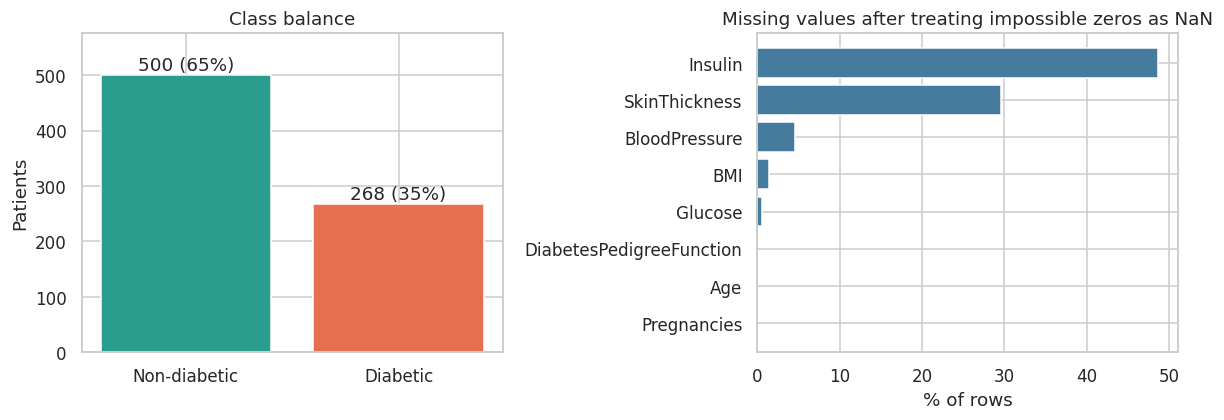

In [3]:
plots.class_balance_and_missing(frame)
plt.show()

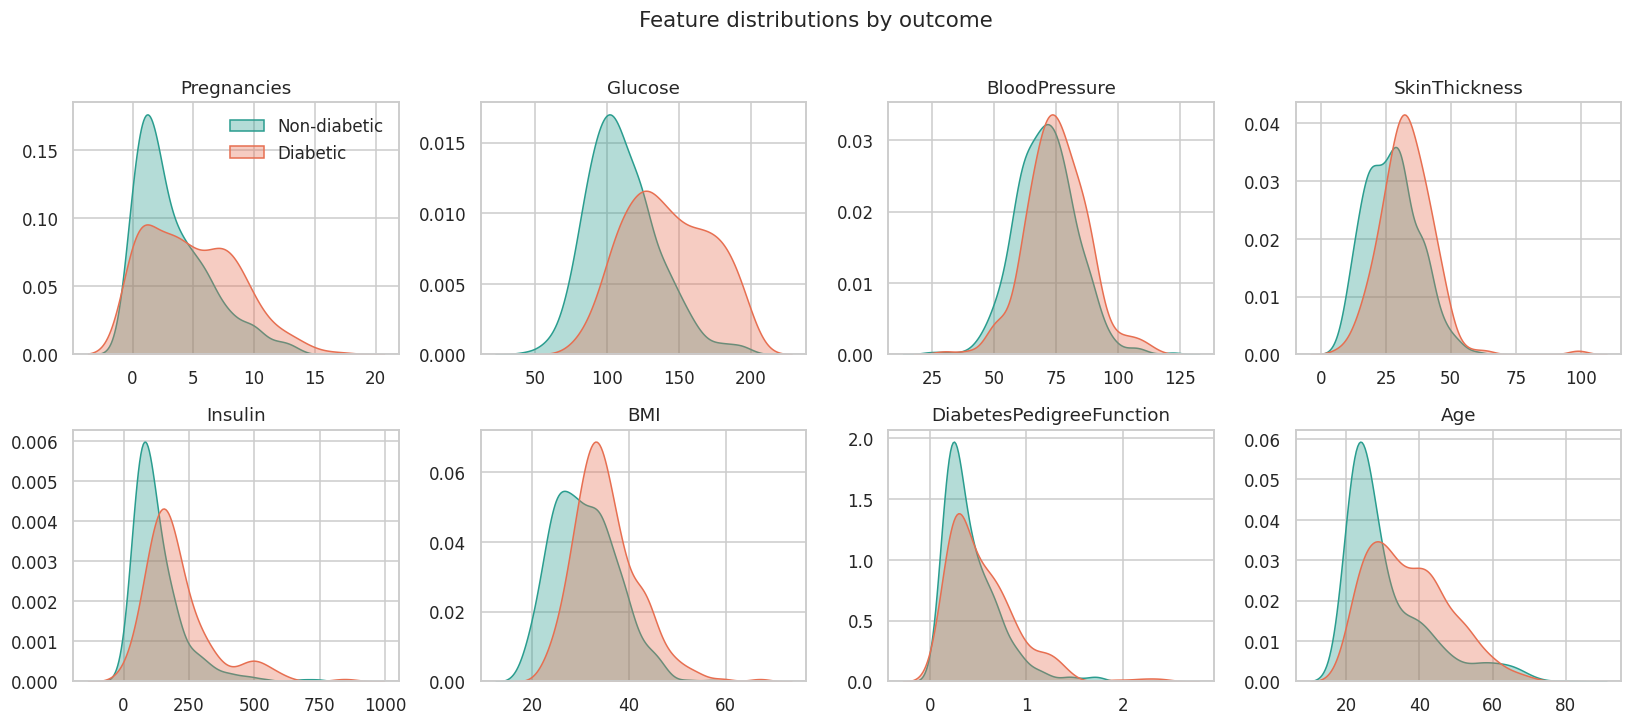

In [4]:
plots.feature_distributions(frame)
plt.show()

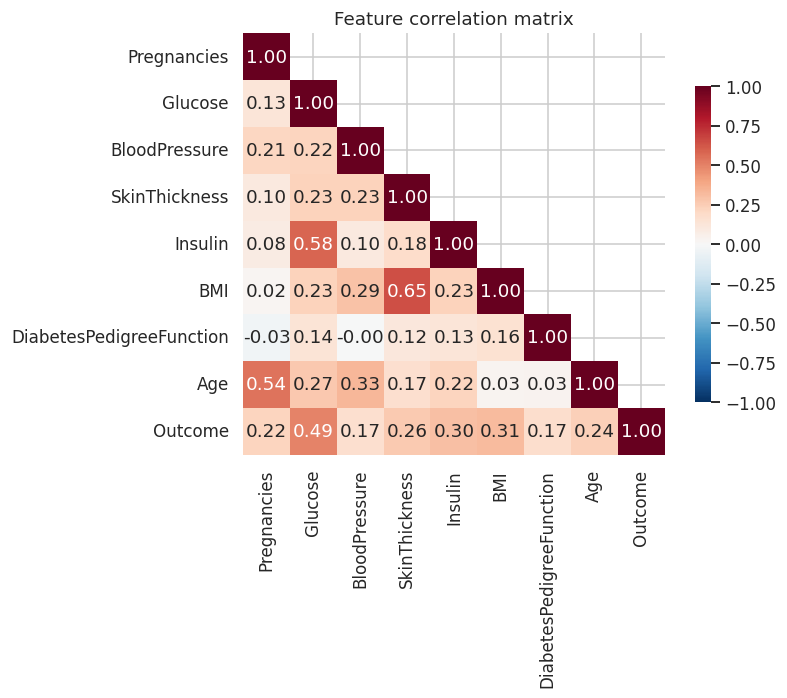

In [5]:
plots.correlation_heatmap(frame)
plt.show()

**Observations**
- About two thirds of patients are non-diabetic, so plain accuracy flatters a model; recall and ROC-AUC matter too.
- Insulin and skin thickness have the most missing values.
- Glucose separates the two groups most clearly, followed by BMI and age.

## 3. Train/test split

The split is stratified so both sets keep the original class ratio. The test set stays untouched until the final evaluation.

In [6]:
X, y = split_features_target(frame)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print('train:', X_train.shape, ' test:', X_test.shape)
print('diabetic share  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

train: (614, 8)  test: (154, 8)
diabetic share  train: 0.349  test: 0.351


## 4. Kernel comparison

Every kernel is wrapped in the same impute -> scale -> SVM pipeline and scored with 5-fold cross-validation on the training split.

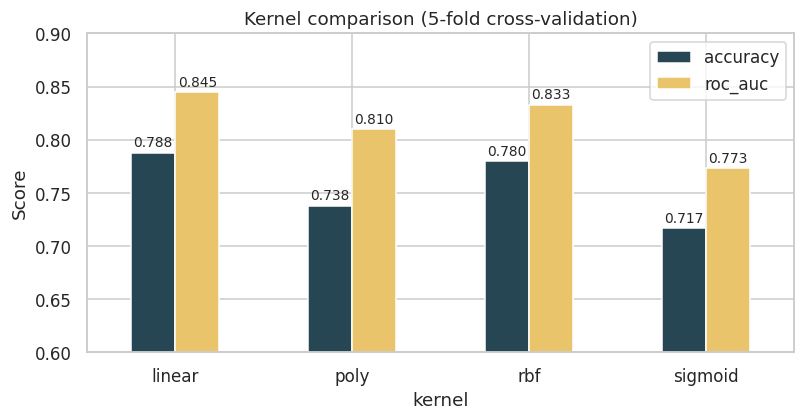

,accuracy,roc_auc
kernel,,
linear,0.788,0.845
poly,0.738,0.810
rbf,0.780,0.833
sigmoid,0.717,0.773


In [7]:
kernel_table = compare_kernels(build_pipeline, X_train, y_train)
plots.kernel_comparison(kernel_table)
plt.show()
kernel_table

## 5. Hyper-parameter tuning

A grid search explores linear and RBF kernels over several `C` / `gamma` values, optimising ROC-AUC.

In [8]:
search = tune_pipeline(X_train, y_train)
print('Best parameters:', search.best_params_)
print('Best CV ROC-AUC: %.3f' % search.best_score_)
model = search.best_estimator_

pd.DataFrame(search.cv_results_)[['param_svm__kernel', 'param_svm__C', 'param_svm__gamma', 'mean_test_score']] \
    .sort_values('mean_test_score', ascending=False).head(6).round(3)

Best parameters: {'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Best CV ROC-AUC: 0.846


,param_svm__kernel,param_svm__C,param_svm__gamma,mean_test_score
8,rbf,1.00,0.01,0.846
0,linear,0.01,NaN,0.846
11,rbf,10.00,0.01,0.845
3,linear,10.00,NaN,0.845
2,linear,1.00,NaN,0.845
1,linear,0.10,NaN,0.844


## 6. Evaluation on held-out data

In [9]:
pd.Series(score_model(model, X_test, y_test)).round(3).to_frame('test set')

,test set
accuracy,0.708
precision,0.610
recall (sensitivity),0.463
specificity,0.840
f1,0.526
roc_auc,0.805


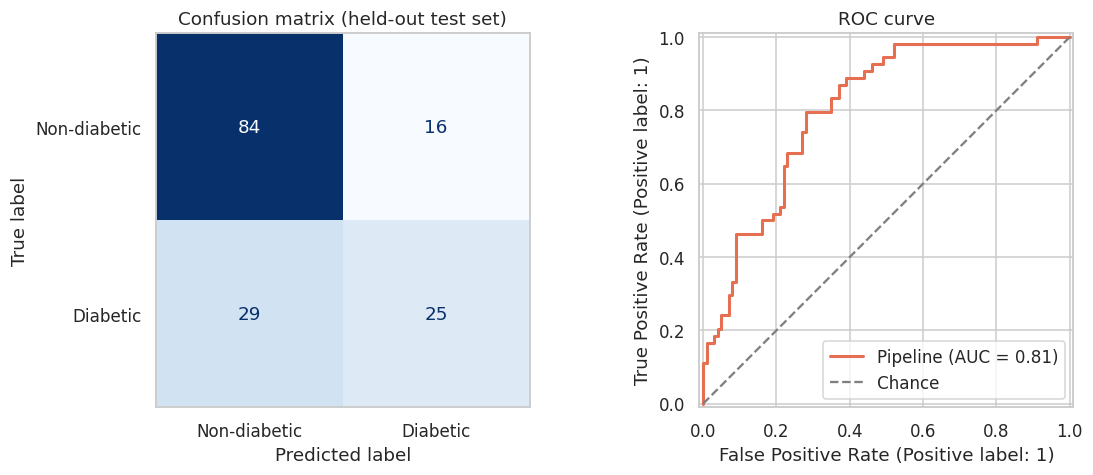

In [10]:
plots.evaluation_panel(model, X_test, y_test)
plt.show()

In [11]:
cross_validated_scores(build_pipeline(kernel=search.best_params_['svm__kernel'],
                                      C=search.best_params_['svm__C'],
                                      gamma=search.best_params_.get('svm__gamma', 'scale')), X_train, y_train)

,mean,std
accuracy,0.777,0.019
precision,0.760,0.061
recall,0.533,0.019
f1,0.625,0.023
roc_auc,0.846,0.011


The model is conservative: it rarely labels a healthy person as diabetic (high specificity) but misses a fair share of true cases (modest recall). For screening, lowering the decision threshold would trade some specificity for recall.

## 7. What drives the predictions?

A non-linear kernel has no simple coefficient vector, so permutation importance is used: shuffle one feature at a time and measure how much ROC-AUC drops.

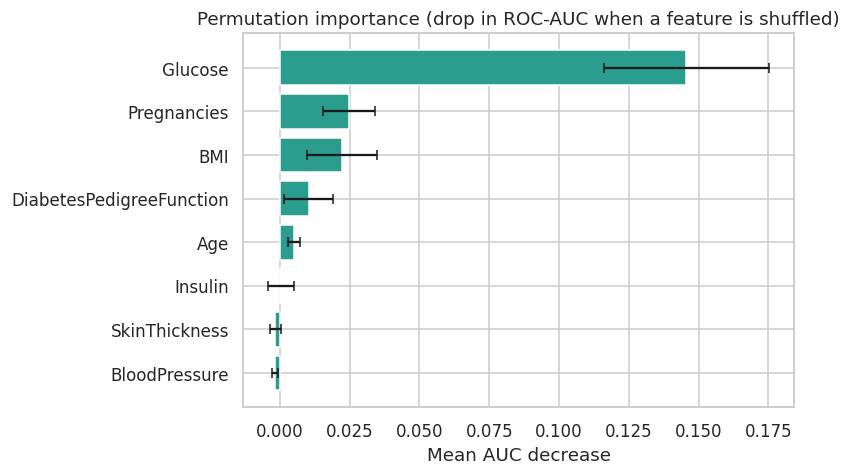

In [12]:
plots.permutation_importance_plot(model, X_test, y_test)
plt.show()

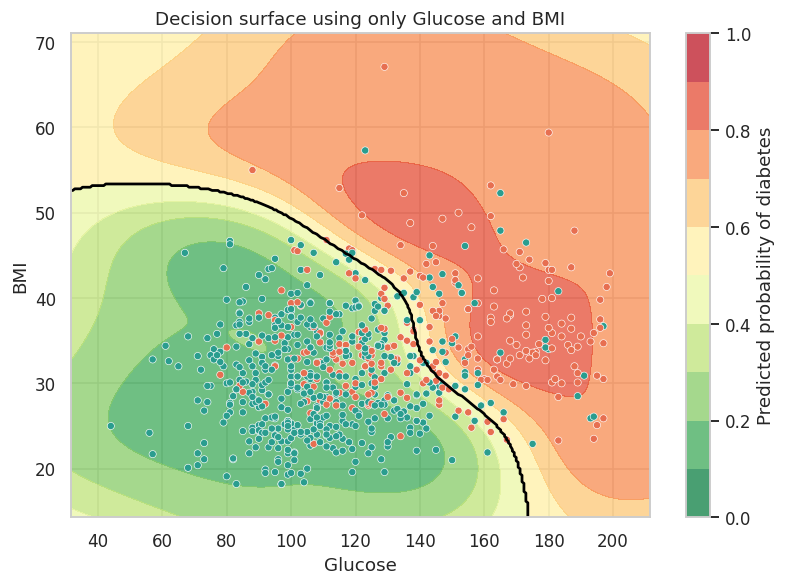

In [13]:
plots.decision_boundary(X, y, build_pipeline)
plt.show()

## 8. Scoring a new person

Measurements that are not available can simply be left out; the pipeline imputes them.

In [14]:
report = predict_risk({
    'Pregnancies': 5, 'Glucose': 166, 'BloodPressure': 72, 'SkinThickness': 19,
    'Insulin': 175, 'BMI': 25.8, 'DiabetesPedigreeFunction': 0.587, 'Age': 51,
}, model=model)
print(report)

Positive screening result (estimated probability 63%, high risk band)


In [15]:
partial = predict_risk({'Glucose': 95, 'BMI': 22.0, 'Age': 29}, model=model)
print(partial)

Negative screening result (estimated probability 6%, low risk band)


> **Disclaimer:** this is an educational model trained on a small, single-population dataset. It is not a diagnostic tool.